# Credit Scoring : prédiction du défaut de paiement (Taïwan, UCI)

**Objectif :** construire un modèle de scoring qui prédit si un client de carte de crédit va **faire défaut le mois suivant**, et comparer trois approches : **régression logistique**, **Random Forest** et **XGBoost**.

**Dataset :** *Default of Credit Card Clients* (UCI Machine Learning Repository, Yeh & Lien, 2009) - clients d'une banque taïwanaise, d'avril à septembre 2005. 23 variables explicatives (limite de crédit, profil, historique de remboursement, montants des factures et des paiements) et une cible binaire `default` (1 = défaut le mois suivant).

**Démarche**

1. Mise en place
2. Chargement et contrôle qualité des données (doublons, valeurs manquantes, modalités incohérentes)
3. Analyse exploratoire (cible, variables numériques et catégorielles, corrélations)
4. Feature engineering
5. Séparation train / test et pré-traitement
6. Modèles de référence (baselines)
7. Optimisation des hyperparamètres par validation croisée (3 modèles)
8. Seuil de décision
9. Évaluation finale sur le jeu de test et comparaison
10. Interprétation des modèles
11. Choix du modèle final, lecture « métier » du score
12. Conclusions

## 1. Mise en place

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import io, zipfile, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
    precision_recall_curve, precision_score, recall_score, f1_score,
    accuracy_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report,
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV,
    cross_val_score, cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from xgboost import XGBClassifier

RANDOM_STATE = 51016
TARGET = "default"
N_JOBS = -1

Path("figures").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
Path("data").mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100


def show(name=None):
    # Enregistre la figure courante dans figures/ (pour le README) puis l'affiche
    if name:
        plt.savefig(f"figures/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 2. Chargement et contrôle qualité des données

### 2.1 Chargement

Le notebook cherche le dataset dans cet ordre :

1. un fichier local dans `data/` (par exemple `default of credit card clients.xls` téléchargé depuis UCI) ;
2. le téléchargement direct depuis UCI (30 000 clients) ;
3. en dernier recours, une copie publique du même dataset sur GitHub (dépôt `pycaret/datasets`, **24 000 clients** = échantillon du fichier UCI, sans la colonne `ID`).

Quelle que soit la source, les colonnes sont harmonisées : `PAY_0` est renommé `PAY_1`, la cible est nommée `default` et `ID` est supprimé.

In [2]:
UCI_ZIP = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
GITHUB_CSV = "https://raw.githubusercontent.com/pycaret/datasets/main/data/common/credit.csv"


def normalize(df):
    # Harmonise les noms de colonnes entre les différentes sources
    df = df.copy()
    df.columns = [str(c).strip().upper() for c in df.columns]
    df = df.rename(columns={"PAY_0": "PAY_1", "DEFAULT PAYMENT NEXT MONTH": "DEFAULT", "DEFAULT.PAYMENT.NEXT.MONTH": "DEFAULT"})
    df = df.drop(columns=["ID"], errors="ignore")
    df = df.rename(columns={"DEFAULT": TARGET})
    return df


def read_uci_excel(src):
    # Le fichier UCI a une ligne de titre parasite avant les noms de colonnes
    return pd.read_excel(src, header=1)


def load_data():
    # 1) fichier local
    local = sorted(Path("data").glob("*"), key=lambda p: (p.suffix.lower() not in {".xls", ".xlsx"}, "github" in p.name))
    for p in local:
        if p.suffix.lower() in {".xls", ".xlsx"}:
            return normalize(read_uci_excel(p)), f"fichier local data/{p.name}"
        if p.suffix.lower() == ".csv":
            note = " (copie GitHub en cache : 24 000 lignes)" if "github" in p.name else ""
            return normalize(pd.read_csv(p)), f"fichier local data/{p.name}{note}"
    # 2) UCI
    try:
        raw = urllib.request.urlopen(UCI_ZIP, timeout=30).read()
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            name = next(n for n in z.namelist() if n.lower().endswith((".xls", ".xlsx")))
            return normalize(read_uci_excel(io.BytesIO(z.read(name)))), "UCI (téléchargement direct)"
    except Exception as e:
        print(f"UCI inaccessible ({type(e).__name__}) -> copie GitHub")
    # 3) copie GitHub, mise en cache dans data/
    df = pd.read_csv(GITHUB_CSV)
    df.to_csv("data/credit_default_github_copy.csv", index=False)
    return normalize(df), "copie GitHub pycaret/datasets (24 000 lignes)"


df_raw, SOURCE = load_data()
print(f"Source : {SOURCE}")
print(f"Dimensions : {df_raw.shape[0]:,} lignes x {df_raw.shape[1]} colonnes")
df_raw.head()

Source : UCI (téléchargement direct)
Dimensions : 30,000 lignes x 24 colonnes


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


### 2.2 Dictionnaire des variables

| Variable | Description |
|---|---|
| `LIMIT_BAL` | Plafond de crédit accordé (en NT$), crédit individuel et familial inclus |
| `SEX` | 1 = homme, 2 = femme |
| `EDUCATION` | 1 = études supérieures (master/doctorat), 2 = université, 3 = lycée, 4 = autres |
| `MARRIAGE` | 1 = marié(e), 2 = célibataire, 3 = autre |
| `AGE` | Âge (années) |
| `PAY_1` ... `PAY_6` | Statut de remboursement de **septembre** (`PAY_1`) à **avril** (`PAY_6`) 2005 : -1 = payé dans les temps, 1 = retard d'un mois, 2 = retard de deux mois, ... 9 = retard de neuf mois ou plus. Les valeurs 0 et -2 ne sont pas documentées (voir 2.4) |
| `BILL_AMT1` ... `BILL_AMT6` | Montant de la facture de septembre (`1`) à avril (`6`) |
| `PAY_AMT1` ... `PAY_AMT6` | Montant payé en septembre (`1`) à avril (`6`) |
| `default` | **Cible** : 1 = défaut de paiement le mois suivant (octobre), 0 = pas de défaut |

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   LIMIT_BAL  30000 non-null  int64
 1   SEX        30000 non-null  int64
 2   EDUCATION  30000 non-null  int64
 3   MARRIAGE   30000 non-null  int64
 4   AGE        30000 non-null  int64
 5   PAY_1      30000 non-null  int64
 6   PAY_2      30000 non-null  int64
 7   PAY_3      30000 non-null  int64
 8   PAY_4      30000 non-null  int64
 9   PAY_5      30000 non-null  int64
 10  PAY_6      30000 non-null  int64
 11  BILL_AMT1  30000 non-null  int64
 12  BILL_AMT2  30000 non-null  int64
 13  BILL_AMT3  30000 non-null  int64
 14  BILL_AMT4  30000 non-null  int64
 15  BILL_AMT5  30000 non-null  int64
 16  BILL_AMT6  30000 non-null  int64
 17  PAY_AMT1   30000 non-null  int64
 18  PAY_AMT2   30000 non-null  int64
 19  PAY_AMT3   30000 non-null  int64
 20  PAY_AMT4   30000 non-null  int64
 21  PAY_AMT5   30000 non-nu

In [4]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.32,129747.66,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.60,0.49,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.85,0.79,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.55,0.52,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.49,9.22,21.0,28.00,34.0,41.00,79.0
PAY_1,30000.0,-0.02,1.12,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.13,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.17,1.20,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.22,1.17,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.27,1.13,-2.0,-1.00,0.0,0.00,8.0


### 2.3 Valeurs manquantes et doublons

In [5]:
missing = df_raw.isna().sum()
print(f"Valeurs manquantes au total : {int(missing.sum())}")
print(missing[missing > 0].to_string() if missing.sum() else "Aucune colonne avec valeur manquante.")

n_dup = df_raw.duplicated().sum()
print(f"\nLignes dupliquées : {n_dup:,} ({n_dup / len(df_raw):.2%})")

# Les doublons sont supprimés *avant* la séparation train/test pour qu'une même ligne ne se retrouve pas des deux côtés
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Dimensions après suppression des doublons : {df.shape}")

Valeurs manquantes au total : 0
Aucune colonne avec valeur manquante.

Lignes dupliquées : 35 (0.12%)
Dimensions après suppression des doublons : (29965, 24)


> Sans identifiant client, deux lignes identiques peuvent en théorie être deux clients différents au profil strictement identique. Ici, avec 23 variables dont 12 montants, c'est très improbable : on les traite comme de vrais doublons. Ils sont peu nombreux, l'impact sur les résultats est négligeable.

### 2.4 Modalités incohérentes

Le dictionnaire UCI ne décrit pas toutes les valeurs observées. On inspecte les variables catégorielles et les statuts de remboursement.

In [6]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"--- {col}")
    print(df[col].value_counts().sort_index().to_string(), "\n")

print("--- PAY_1")
print(df["PAY_1"].value_counts().sort_index().to_string())

--- SEX
SEX
1    11874
2    18091 

--- EDUCATION
EDUCATION
0       14
1    10563
2    14019
3     4915
4      123
5      280
6       51 

--- MARRIAGE
MARRIAGE
0       54
1    13643
2    15945
3      323 

--- PAY_1
PAY_1
-2     2750
-1     5682
 0    14737
 1     3667
 2     2666
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19


- `EDUCATION` contient les valeurs **0, 5 et 6**, absentes de la documentation : elles sont regroupées avec `4` (« autres »).
- `MARRIAGE` contient la valeur **0**, non documentée : regroupée avec `3` (« autre »).
- Dans `PAY_x`, **-2** (pas de consommation) et **0** (utilisation du crédit renouvelable, paiement du minimum) ne sont pas documentés officiellement mais sont très fréquents. On les **conserve**. L'échelle est bien ordonnée pour les retards (≥ 1 : le taux de défaut augmente avec le nombre de mois, voir 3.4), mais pas strictement en dessous : le taux de défaut est de 12,8 % pour `0`, 13,2 % pour `-2` et 16,8 % pour `-1`. Les arbres s'en accommodent (ils découpent librement les valeurs) ; pour la régression logistique, traiter `PAY_x` comme une variable numérique est une approximation, que l'agrégat `n_late_months` (nombre de retards > 0) complète.
- Les `BILL_AMT` négatifs (client créditeur après un trop-perçu) sont des valeurs réelles : on les conserve.

In [7]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

print(df["EDUCATION"].value_counts().sort_index().to_string())
print()
print(df["MARRIAGE"].value_counts().sort_index().to_string())
print(f"\nFactures négatives : {(df.filter(like='BILL_AMT') < 0).any(axis=1).sum():,} clients concernés")
print(f"Paiements négatifs : {(df.filter(like='PAY_AMT') < 0).any(axis=1).sum()} clients concernés")

EDUCATION
1    10563
2    14019
3     4915
4      468

MARRIAGE
1    13643
2    15945
3      377

Factures négatives : 1,930 clients concernés
Paiements négatifs : 0 clients concernés


## 3. Analyse exploratoire

### 3.1 Distribution de la cible

default
0    0.7787
1    0.2213


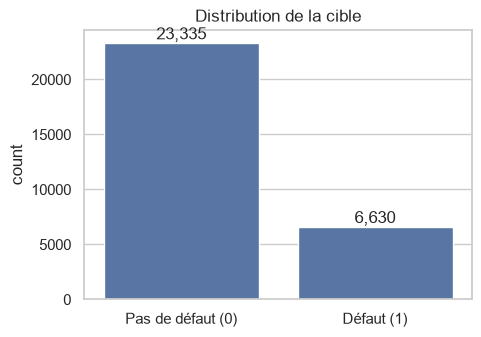

In [8]:
print(df[TARGET].value_counts(normalize=True).rename("proportion").round(4).to_string())

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x=TARGET, ax=ax)
ax.set_xticks([0, 1], ["Pas de défaut (0)", "Défaut (1)"])
ax.set_xlabel("")
ax.set_title("Distribution de la cible")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
show("01_target")

La cible est **déséquilibrée** (environ 22 % de défauts, soit environ 1 client sur 4,5). Conséquences :

- l'accuracy seule est trompeuse : un modèle qui prédit toujours « pas de défaut » atteint déjà ~78 % ;
- le découpage train/test et la validation croisée doivent être **stratifiés** ;
- les modèles seront comparés sur des métriques adaptées : **ROC-AUC**, **PR-AUC**, **KS**, ainsi que rappel / précision / F1 de la classe « défaut ».

### 3.2 Variables numériques

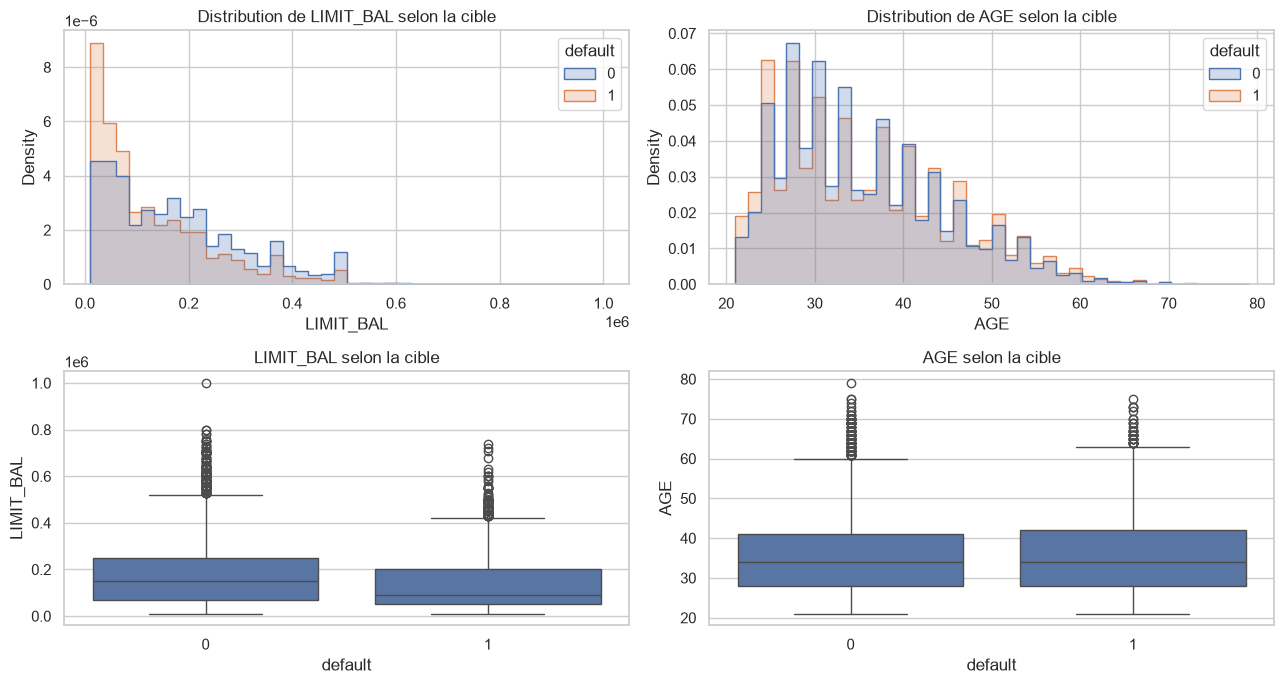

In [9]:
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAYAMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]
PAY_COLS = [f"PAY_{i}" for i in range(1, 7)]
CAT_COLS = ["SEX", "EDUCATION", "MARRIAGE"]

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for j, col in enumerate(["LIMIT_BAL", "AGE"]):
    sns.histplot(data=df, x=col, hue=TARGET, bins=40, stat="density", common_norm=False, element="step", ax=axes[0, j])
    axes[0, j].set_title(f"Distribution de {col} selon la cible")
    sns.boxplot(data=df, x=TARGET, y=col, ax=axes[1, j])
    axes[1, j].set_title(f"{col} selon la cible")
plt.tight_layout()
show("02_limit_age")

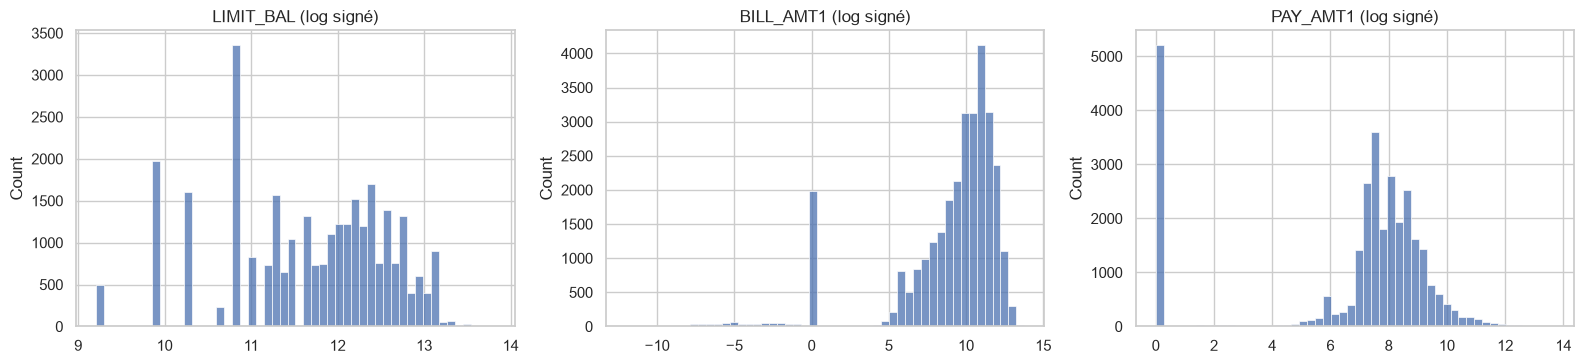

Asymétrie (skewness) :
LIMIT_BAL     0.99
BILL_AMT1     2.66
PAY_AMT1     14.66


In [10]:
# Les montants sont très asymétriques (quelques très grosses valeurs) : on regarde leur forme en échelle log signée
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col in zip(axes, ["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]):
    sns.histplot(signed_log(df[col]), bins=50, ax=ax)
    ax.set_title(f"{col} (log signé)")
    ax.set_xlabel("")
plt.tight_layout()
show()

print("Asymétrie (skewness) :")
print(df[["LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]].skew().round(2).to_string())

In [11]:
# Détection d'outliers avec la règle 1,5 x IQR
rows = []
for col in ["LIMIT_BAL", "AGE"] + BILL_COLS + PAYAMT_COLS:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    rows.append({"variable": col, "n_outliers": int(mask.sum()), "part": f"{mask.mean():.1%}"})
pd.DataFrame(rows)

,variable,n_outliers,part
0,LIMIT_BAL,167,0.6%
1,AGE,272,0.9%
2,BILL_AMT1,2386,8.0%
3,BILL_AMT2,2390,8.0%
4,BILL_AMT3,2469,8.2%
5,BILL_AMT4,2616,8.7%
6,BILL_AMT5,2724,9.1%
7,BILL_AMT6,2688,9.0%
8,PAY_AMT1,2742,9.2%
9,PAY_AMT2,2723,9.1%


Les montants ont des queues lourdes : environ 8 à 10 % des factures et des paiements sont « atypiques » au sens de l'IQR (contre moins de 1 % pour `LIMIT_BAL` et `AGE`), mais ce sont de vrais clients à gros encours, pas des erreurs de saisie. **On ne supprime donc aucun outlier**. Le traitement dépend du modèle :

- **Random Forest / XGBoost** : insensibles aux transformations monotones et aux valeurs extrêmes (les coupures ne dépendent que de l'ordre des valeurs) ;
- **Régression logistique** : sensible à l'échelle et aux queues lourdes, donc les montants seront passés en **log signé** puis **standardisés** dans le pipeline.

### 3.3 Variables catégorielles

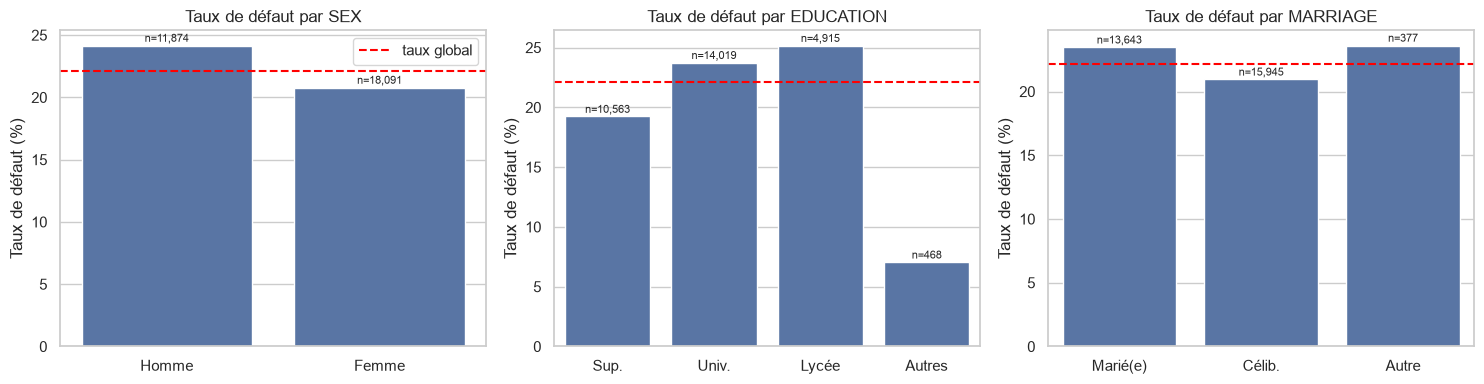

SEX        chi2 =    47.1 | p = 6.64e-12 | V de Cramér = 0.040
EDUCATION  chi2 =   160.5 | p = 1.46e-34 | V de Cramér = 0.073
MARRIAGE   chi2 =    27.5 | p = 1.07e-06 | V de Cramér = 0.030


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = {
    "SEX": {1: "Homme", 2: "Femme"},
    "EDUCATION": {1: "Sup.", 2: "Univ.", 3: "Lycée", 4: "Autres"},
    "MARRIAGE": {1: "Marié(e)", 2: "Célib.", 3: "Autre"},
}
for ax, col in zip(axes, CAT_COLS):
    g = df.groupby(col)[TARGET].agg(["mean", "size"])
    sns.barplot(x=g.index.map(labels[col]), y=g["mean"] * 100, ax=ax)
    ax.axhline(df[TARGET].mean() * 100, color="red", linestyle="--", label="taux global")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m * 100 + 0.3, f"n={n:,}", ha="center", fontsize=8)
    ax.set_title(f"Taux de défaut par {col}")
    ax.set_ylabel("Taux de défaut (%)")
    ax.set_xlabel("")
axes[0].legend()
plt.tight_layout()
show("03_categorical")

# Test du chi-deux d'indépendance avec la cible
for col in CAT_COLS:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[col], df[TARGET]))
    n = len(df)
    cramers_v = np.sqrt(chi2 / (n * (min(pd.crosstab(df[col], df[TARGET]).shape) - 1)))
    print(f"{col:10s} chi2 = {chi2:7.1f} | p = {p:.2e} | V de Cramér = {cramers_v:.3f}")

Les trois variables sont statistiquement liées à la cible (n est grand, donc les p-values sont très faibles), mais les **V de Cramér sont faibles** (< 0,1) : l'effet pratique est limité. Ce sont des variables secondaires.

### 3.4 Historique de remboursement : le signal principal

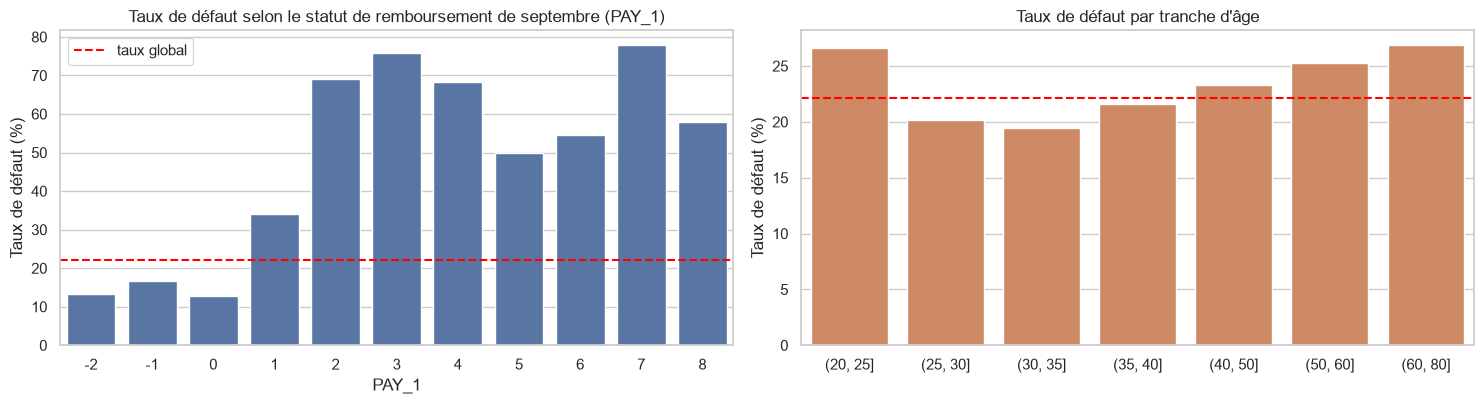

PAY_1                -2      -1        0       1       2      3     4     5     6     7     8
taux défaut (%)    13.2    16.8     12.8    34.0    69.1   75.8  68.4  50.0  54.5  77.8  57.9
effectif         2750.0  5682.0  14737.0  3667.0  2666.0  322.0  76.0  26.0  11.0   9.0  19.0


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))

g = df.groupby("PAY_1")[TARGET].agg(["mean", "size"])
sns.barplot(x=g.index, y=g["mean"] * 100, ax=axes[0], color=sns.color_palette()[0])
axes[0].axhline(df[TARGET].mean() * 100, color="red", linestyle="--", label="taux global")
axes[0].set_title("Taux de défaut selon le statut de remboursement de septembre (PAY_1)")
axes[0].set_ylabel("Taux de défaut (%)")
axes[0].legend()

age_bins = pd.cut(df["AGE"], [20, 25, 30, 35, 40, 50, 60, 80])
g2 = df.groupby(age_bins, observed=True)[TARGET].mean() * 100
sns.barplot(x=g2.index.astype(str), y=g2.values, ax=axes[1], color=sns.color_palette()[1])
axes[1].axhline(df[TARGET].mean() * 100, color="red", linestyle="--")
axes[1].set_title("Taux de défaut par tranche d'âge")
axes[1].set_ylabel("Taux de défaut (%)")
axes[1].set_xlabel("")
plt.tight_layout()
show("04_pay1_age")

print(g.assign(mean=lambda x: (x["mean"] * 100).round(1)).rename(columns={"mean": "taux défaut (%)", "size": "effectif"}).T.to_string())

Le statut de remboursement récent est **de loin** le signal le plus fort : le taux de défaut est d'environ 13-17 % pour les clients à jour (`PAY_1` = -2, -1 ou 0), monte à ~34 % pour un mois de retard et atteint ~70 % à deux mois de retard (au-delà de 3 mois, les effectifs sont trop faibles pour être lus individuellement : de 50 à 78 % selon la modalité). L'âge et les caractéristiques socio-démographiques jouent un rôle bien plus modeste.

### 3.5 Corrélations

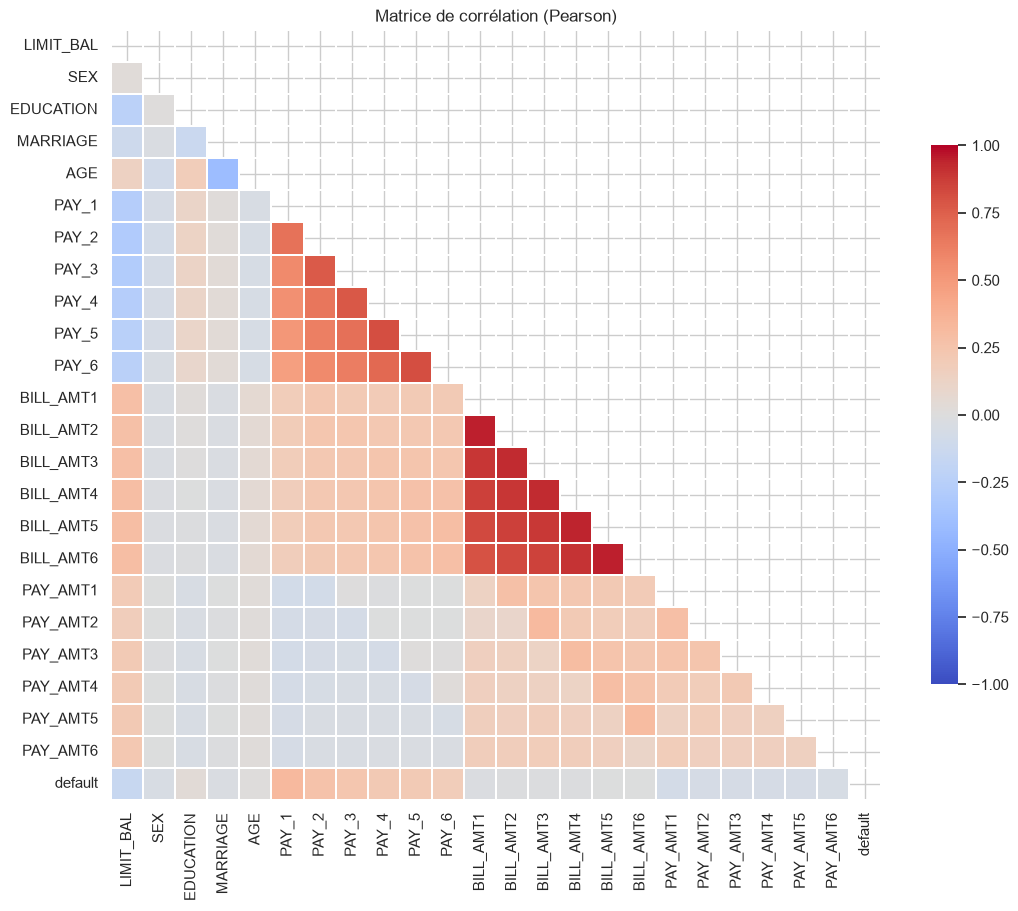

Corrélation avec la cible :
PAY_1        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
LIMIT_BAL   -0.154
PAY_AMT1    -0.073
PAY_AMT2    -0.059
PAY_AMT4    -0.057
PAY_AMT3    -0.056
PAY_AMT5    -0.055


In [14]:
corr = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, linewidths=0.2,
            cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Matrice de corrélation (Pearson)")
show("05_correlation")

print("Corrélation avec la cible :")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).head(12).to_string())

In [15]:
# Multicolinéarité : paires de variables très corrélées entre elles
pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
             .stack().rename("corr").reset_index()
             .rename(columns={"level_0": "var_1", "level_1": "var_2"}))
strong = pairs[(pairs["corr"].abs() > 0.8) & (pairs["var_1"] != TARGET) & (pairs["var_2"] != TARGET)]
print(f"{len(strong)} paires avec |corr| > 0,8 :")
strong.sort_values("corr", ascending=False).round(3).reset_index(drop=True)

17 paires avec |corr| > 0,8 :


,var_1,var_2,corr
0,BILL_AMT1,BILL_AMT2,0.951
1,BILL_AMT5,BILL_AMT6,0.946
2,BILL_AMT4,BILL_AMT5,0.940
3,BILL_AMT2,BILL_AMT3,0.928
4,BILL_AMT3,BILL_AMT4,0.924
5,BILL_AMT4,BILL_AMT6,0.901
6,BILL_AMT2,BILL_AMT4,0.892
7,BILL_AMT1,BILL_AMT3,0.892
8,BILL_AMT3,BILL_AMT5,0.884
9,BILL_AMT1,BILL_AMT4,0.860


- Les `PAY_1` ... `PAY_6` sont les plus corrélées à la cible (surtout `PAY_1`, puis `PAY_2`, ...). `LIMIT_BAL` suit avec une corrélation négative modérée (≈ -0,15 : plus le plafond est élevé, moins le risque est fort). Les factures, les paiements et l'âge n'ont qu'une corrélation linéaire faible avec la cible.
- Les six `BILL_AMT` sont **fortement corrélées entre elles** (jusqu'à > 0,9 : la facture d'un mois dépend de celle du mois précédent) ; les `PAY_x` successifs le sont aussi. C'est un problème de **multicolinéarité** pour la régression logistique (coefficients instables, difficiles à interpréter) mais pas pour les arbres. On l'atténue par la régularisation L2 et par des variables agrégées (section 4).

## 4. Feature engineering

Quelques variables synthétiques, inspirées du métier du crédit, résument les 18 colonnes de montants et de statuts :

| Variable | Définition | Intuition |
|---|---|---|
| `n_late_months` | nombre de mois (sur 6) avec un retard (`PAY_x` > 0) | récurrence des retards |
| `max_delay` | plus grand retard observé (`max` des `PAY_x`) | gravité maximale |
| `mean_pay_status` | moyenne des `PAY_x` | tendance générale |
| `avg_bill` | moyenne des six factures | niveau d'endettement moyen |
| `util_last` | `BILL_AMT1 / LIMIT_BAL` | taux d'utilisation du plafond le dernier mois |
| `util_avg` | `avg_bill / LIMIT_BAL` | taux d'utilisation moyen |
| `pay_ratio` | total payé / total facturé (borné entre 0 et 1) | capacité à rembourser |

Ces variables sont calculées **ligne par ligne**, sans utiliser la cible ni des statistiques globales : elles ne créent donc aucune fuite d'information entre train et test.

In [16]:
def add_features(d):
    d = d.copy()
    d["n_late_months"] = (d[PAY_COLS] > 0).sum(axis=1)
    d["max_delay"] = d[PAY_COLS].max(axis=1)
    d["mean_pay_status"] = d[PAY_COLS].mean(axis=1)
    d["avg_bill"] = d[BILL_COLS].mean(axis=1)
    d["util_last"] = d["BILL_AMT1"] / d["LIMIT_BAL"]
    d["util_avg"] = d["avg_bill"] / d["LIMIT_BAL"]
    total_bill = d[BILL_COLS].clip(lower=0).sum(axis=1)
    d["pay_ratio"] = (d[PAYAMT_COLS].sum(axis=1) / total_bill.where(total_bill > 0)).fillna(1.0).clip(0, 1)
    return d

NEW_FEATS = ["n_late_months", "max_delay", "mean_pay_status", "avg_bill", "util_last", "util_avg", "pay_ratio"]
df_fe = add_features(df)
print(df_fe[NEW_FEATS].describe().T.round(3).to_string())
print("\nCorrélation avec la cible :")
print(df_fe[NEW_FEATS + [TARGET]].corr()[TARGET].drop(TARGET).round(3).sort_values(key=abs, ascending=False).to_string())

                   count       mean        std        min       25%        50%        75%         max
n_late_months    29965.0      0.834      1.555      0.000     0.000      0.000      1.000       6.000
max_delay        29965.0      0.439      1.345     -2.000     0.000      0.000      2.000       8.000
mean_pay_status  29965.0     -0.181      0.981     -2.000    -0.833      0.000      0.000       6.000
avg_bill         29965.0  45029.328  63279.074 -56043.167  4841.000  21110.833  57166.167  877313.833
util_last        29965.0      0.424      0.411     -0.620     0.022      0.315      0.830       6.455
util_avg         29965.0      0.373      0.352     -0.233     0.030      0.286      0.688       5.364
pay_ratio        29965.0      0.345      0.381      0.000     0.043      0.106      0.712       1.000

Corrélation avec la cible :
n_late_months      0.398
max_delay          0.331
mean_pay_status    0.282
util_avg           0.115
pay_ratio         -0.090
util_last          0.086
avg_b

## 5. Séparation train / test et pré-traitement

- Découpage **80 / 20 stratifié** sur la cible ; le jeu de test n'est utilisé **qu'à la fin**, pour l'évaluation finale.
- Toute la sélection (hyperparamètres, seuil, choix du modèle) se fait par **validation croisée stratifiée à 5 plis sur le train uniquement**.
- Le pré-traitement est inclus dans un `Pipeline` : il est refait à chaque pli, ce qui évite toute fuite d'information.
- `SEX`, `EDUCATION`, `MARRIAGE` sont encodées en *one-hot* (modalités nominales). Pour la régression logistique, les montants sont en log signé puis standardisés, les autres variables numériques sont standardisées. Pour les arbres, les variables numériques sont laissées telles quelles.

In [17]:
X = df_fe.drop(columns=TARGET)
y = df_fe[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train : {X_train.shape} | Test : {X_test.shape}")
print(f"Taux de défaut - train : {y_train.mean():.3%} | test : {y_test.mean():.3%}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train : (23972, 30) | Test : (5993, 30)
Taux de défaut - train : 22.126% | test : 22.126%


In [18]:
MONEY_COLS = ["LIMIT_BAL", "avg_bill"] + BILL_COLS + PAYAMT_COLS


def build_preprocessor(columns, linear):
    # Pré-traitement adapté au type de modèle ('linear' = régression logistique)
    cat = [c for c in CAT_COLS if c in columns]
    money = [c for c in MONEY_COLS if c in columns]
    other = [c for c in columns if c not in cat and c not in money]
    if linear:
        return ColumnTransformer(
            [
                ("money", Pipeline([("log", FunctionTransformer(signed_log, feature_names_out="one-to-one")),
                                    ("scale", StandardScaler())]), money),
                ("num", StandardScaler(), other),
                ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat),
            ],
            verbose_feature_names_out=False,
        )
    return ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )


ALL_FEATS = X_train.columns.tolist()
RAW_FEATS = [c for c in ALL_FEATS if c not in NEW_FEATS]


def make_lr(columns, **kw):
    return Pipeline([("prep", build_preprocessor(columns, linear=True)),
                     ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE, **kw))])


def make_rf(columns, **kw):
    return Pipeline([("prep", build_preprocessor(columns, linear=False)),
                     ("clf", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=N_JOBS, **kw))])


def make_xgb(columns, **kw):
    return Pipeline([("prep", build_preprocessor(columns, linear=False)),
                     ("clf", XGBClassifier(tree_method="hist", eval_metric="logloss",
                                           random_state=RANDOM_STATE, n_jobs=N_JOBS, **kw))])

## 6. Modèles de référence (baselines)

Deux points de comparaison avant toute optimisation :

1. un **classifieur naïf** (toujours la classe majoritaire) ;
2. les trois modèles avec leurs **hyperparamètres par défaut**, évalués en validation croisée sur le train.

On teste aussi l'apport du **feature engineering** : mêmes modèles avec les variables d'origine seules vs avec les variables synthétiques.

In [19]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Classifieur naïf - accuracy test : {dummy.score(X_test, y_test):.4f} "
      f"(mais ROC-AUC = 0,5 et rappel = 0 sur les défauts)\n")

rows = []
for name, maker in [("Régression logistique", make_lr), ("Random Forest", make_rf), ("XGBoost", make_xgb)]:
    for label, cols in [("variables d'origine", RAW_FEATS), ("+ feature engineering", ALL_FEATS)]:
        scores = cross_val_score(maker(cols), X_train[cols], y_train, cv=cv, scoring="roc_auc", n_jobs=1)
        rows.append({"modèle": name, "variables": label, "ROC-AUC CV (moyenne)": scores.mean(), "écart-type": scores.std()})
baseline_cv = pd.DataFrame(rows)
baseline_cv.round(4)

Classifieur naïf - accuracy test : 0.7787 (mais ROC-AUC = 0,5 et rappel = 0 sur les défauts)



,modèle,variables,ROC-AUC CV (moyenne),écart-type
0,Régression logistique,variables d'origine,0.7452,0.0061
1,Régression logistique,+ feature engineering,0.7614,0.0079
2,Random Forest,variables d'origine,0.7599,0.0103
3,Random Forest,+ feature engineering,0.7617,0.0063
4,XGBoost,variables d'origine,0.7566,0.0071
5,XGBoost,+ feature engineering,0.7598,0.0066


In [20]:
pivot = baseline_cv.pivot(index="modèle", columns="variables", values="ROC-AUC CV (moyenne)")
pivot["gain"] = pivot["+ feature engineering"] - pivot["variables d'origine"]
pivot.round(4)

variables,+ feature engineering,variables d'origine,gain
modèle,,,
Random Forest,0.7617,0.7599,0.0018
Régression logistique,0.7614,0.7452,0.0162
XGBoost,0.7598,0.7566,0.0033


Avec leurs réglages par défaut, les trois modèles sont déjà proches : ROC-AUC en validation croisée d'environ 0,75 à 0,76. Le **feature engineering** apporte un gain net à la **régression logistique** (+0,016 de ROC-AUC) et très peu aux modèles d'arbres (+0,002 et +0,003) : c'est logique, les arbres savent déjà combiner les `PAY_x` et les montants par leurs coupures successives, alors que le modèle linéaire a besoin qu'on lui fournisse ces agrégats (`n_late_months`, etc.). **Dans la suite, tous les modèles utilisent le même jeu de variables (avec feature engineering)** pour que la comparaison reste équitable.

## 7. Optimisation des hyperparamètres

Chaque modèle est optimisé par validation croisée stratifiée à 5 plis sur le train. Le critère est le **ROC-AUC** (qualité du classement des clients, indépendante du seuil de décision et peu sensible au déséquilibre) ; la PR-AUC est suivie en parallèle.

- **Régression logistique** : grille sur la régularisation `C` et sur `class_weight`.
- **Random Forest** et **XGBoost** : recherche aléatoire (`RandomizedSearchCV`) dans des espaces d'hyperparamètres orientés vers la **régularisation** (profondeur limitée, feuilles minimales, sous-échantillonnage), car ces modèles sur-apprennent facilement sur ce type de données.

In [21]:
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}
searches = {}

# --- Régression logistique
searches["Régression logistique"] = GridSearchCV(
    make_lr(ALL_FEATS),
    {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100], "clf__class_weight": [None, "balanced"]},
    cv=cv, scoring=SCORING, refit="roc_auc", n_jobs=1,
).fit(X_train, y_train)
print("Régression logistique :", searches["Régression logistique"].best_params_,
      f"| ROC-AUC CV = {searches['Régression logistique'].best_score_:.4f}")

Régression logistique : {'clf__C': 0.1, 'clf__class_weight': 'balanced'} | ROC-AUC CV = 0.7648


In [22]:
# --- Random Forest
rf_space = {
    "clf__n_estimators": [200, 300, 500],
    "clf__max_depth": [5, 7, 9, 12, None],
    "clf__min_samples_leaf": [1, 5, 10, 20, 40],
    "clf__max_features": ["sqrt", 0.3, 0.5],
    "clf__class_weight": [None, "balanced_subsample"],
}
searches["Random Forest"] = RandomizedSearchCV(
    make_rf(ALL_FEATS), rf_space, n_iter=14, cv=cv, scoring=SCORING, refit="roc_auc",
    random_state=RANDOM_STATE, n_jobs=1,
).fit(X_train, y_train)
print("Random Forest :", searches["Random Forest"].best_params_,
      f"| ROC-AUC CV = {searches['Random Forest'].best_score_:.4f}")

Random Forest : {'clf__n_estimators': 200, 'clf__min_samples_leaf': 40, 'clf__max_features': 0.5, 'clf__max_depth': 9, 'clf__class_weight': None} | ROC-AUC CV = 0.7838


In [23]:
# --- XGBoost
neg_pos = float((y_train == 0).sum() / (y_train == 1).sum())
xgb_space = {
    "clf__n_estimators": [150, 300, 500, 800],
    "clf__learning_rate": [0.01, 0.02, 0.05, 0.1],
    "clf__max_depth": [2, 3, 4, 5, 6],
    "clf__min_child_weight": [1, 5, 10, 20],
    "clf__subsample": [0.6, 0.8, 1.0],
    "clf__colsample_bytree": [0.5, 0.7, 1.0],
    "clf__reg_lambda": [1, 5, 10, 30],
    "clf__gamma": [0, 0.5, 1, 3],
    "clf__scale_pos_weight": [1, neg_pos],
}
searches["XGBoost"] = RandomizedSearchCV(
    make_xgb(ALL_FEATS), xgb_space, n_iter=24, cv=cv, scoring=SCORING, refit="roc_auc",
    random_state=RANDOM_STATE, n_jobs=1,
).fit(X_train, y_train)
print("XGBoost :", searches["XGBoost"].best_params_,
      f"| ROC-AUC CV = {searches['XGBoost'].best_score_:.4f}")

XGBoost : {'clf__subsample': 0.8, 'clf__scale_pos_weight': 3.519607843137255, 'clf__reg_lambda': 30, 'clf__n_estimators': 300, 'clf__min_child_weight': 5, 'clf__max_depth': 4, 'clf__learning_rate': 0.02, 'clf__gamma': 0.5, 'clf__colsample_bytree': 0.5} | ROC-AUC CV = 0.7856


In [24]:
# Récapitulatif des résultats de validation croisée
# (l'écart entre le ROC-AUC sur le train complet et celui en validation croisée détecte le sur-apprentissage)
cv_summary = []
for name, s in searches.items():
    r = pd.DataFrame(s.cv_results_).iloc[s.best_index_]
    auc_train = roc_auc_score(y_train, s.best_estimator_.predict_proba(X_train)[:, 1])
    cv_summary.append({
        "modèle": name,
        "ROC-AUC CV": r["mean_test_roc_auc"], "± écart-type": r["std_test_roc_auc"],
        "PR-AUC CV": r["mean_test_pr_auc"],
        "ROC-AUC train (réajusté)": auc_train,
        "écart train - CV": auc_train - r["mean_test_roc_auc"],
    })
cv_summary = pd.DataFrame(cv_summary).set_index("modèle")
cv_summary.round(4)

,ROC-AUC CV,± écart-type,PR-AUC CV,ROC-AUC train (réajusté),écart train - CV
modèle,,,,,
Régression logistique,0.7648,0.0083,0.5107,0.7675,0.0027
Random Forest,0.7838,0.0067,0.5597,0.8301,0.0464
XGBoost,0.7856,0.0069,0.5626,0.8052,0.0195


La colonne « écart train - CV » mesure le **sur-apprentissage** : un écart important signale que le modèle mémorise le train plutôt que de généraliser. On constate que (i) la régression logistique ne sur-apprend pas du tout mais plafonne plus bas, (ii) **Random Forest et XGBoost gagnent environ 0,02 de ROC-AUC** sur elle et sont proches l'un de l'autre, (iii) la **régularisation compte beaucoup** : le Random Forest passe d'environ 0,762 (réglages par défaut) à 0,784 une fois la profondeur et la taille minimale des feuilles contraintes, et (iv) le Random Forest garde le plus gros écart train / CV (sur-apprentissage), XGBoost un écart plus modéré.

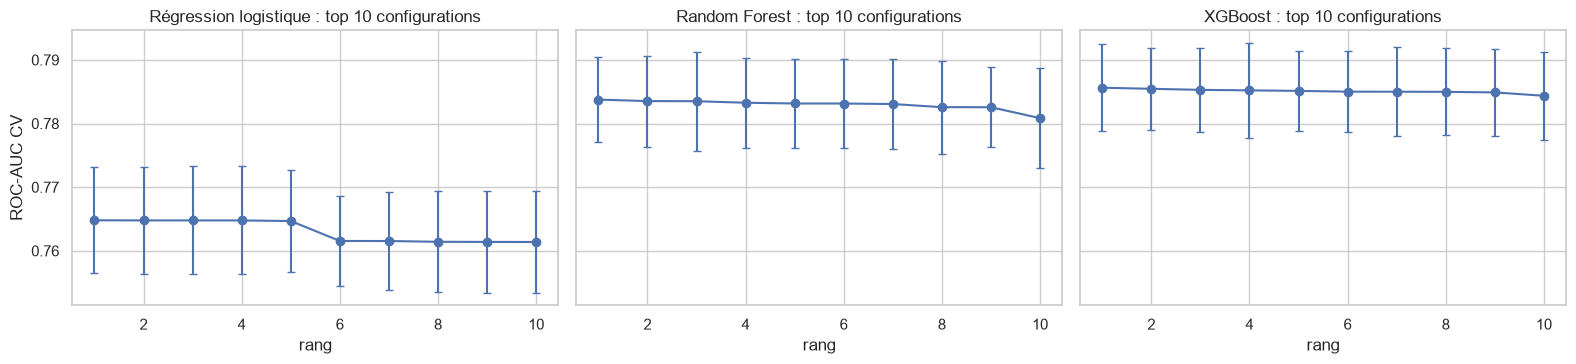

In [25]:
# Sensibilité aux hyperparamètres : meilleurs scores CV de chaque recherche
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, (name, s) in zip(axes, searches.items()):
    r = pd.DataFrame(s.cv_results_).sort_values("rank_test_roc_auc").head(10)
    ax.errorbar(range(1, len(r) + 1), r["mean_test_roc_auc"], yerr=r["std_test_roc_auc"], fmt="o-", capsize=3)
    ax.set_title(f"{name} : top 10 configurations")
    ax.set_xlabel("rang")
axes[0].set_ylabel("ROC-AUC CV")
plt.tight_layout()
show()

## 8. Seuil de décision

Un modèle de scoring produit une **probabilité de défaut**. Pour décider (accorder / refuser, ou surveiller), il faut un **seuil**. Le seuil par défaut de 0,5 est mal adapté quand 22 % seulement des clients sont en défaut : pour un modèle non pondéré comme le Random Forest, il rate beaucoup de défauts (F1 de 0,47 au lieu de 0,55 au seuil optimal). Un modèle entraîné avec pondération des classes (la régression logistique et XGBoost, ici) ramène déjà ses scores vers un seuil proche de 0,5.

Pour chaque modèle, le seuil est choisi pour **maximiser le F1-score de la classe « défaut »** sur les prédictions *out-of-fold* du train (obtenues par validation croisée). Le jeu de test n'intervient pas dans ce choix.

In [26]:
def best_threshold(y_true, proba):
    prec, rec, thr = precision_recall_curve(y_true, proba)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = np.argmax(f1)
    return float(thr[i]), float(f1[i])


oof, thresholds = {}, {}
for name, s in searches.items():
    oof[name] = cross_val_predict(clone(s.best_estimator_), X_train, y_train, cv=cv,
                                  method="predict_proba", n_jobs=1)[:, 1]
    thresholds[name], f1_oof = best_threshold(y_train, oof[name])
    print(f"{name:22s} seuil optimal = {thresholds[name]:.3f} | F1 out-of-fold = {f1_oof:.4f} "
          f"| F1 au seuil 0,5 = {f1_score(y_train, oof[name] >= 0.5):.4f}")

Régression logistique  seuil optimal = 0.543 | F1 out-of-fold = 0.5298 | F1 au seuil 0,5 = 0.5244


Random Forest          seuil optimal = 0.286 | F1 out-of-fold = 0.5458 | F1 au seuil 0,5 = 0.4694


XGBoost                seuil optimal = 0.557 | F1 out-of-fold = 0.5478 | F1 au seuil 0,5 = 0.5362


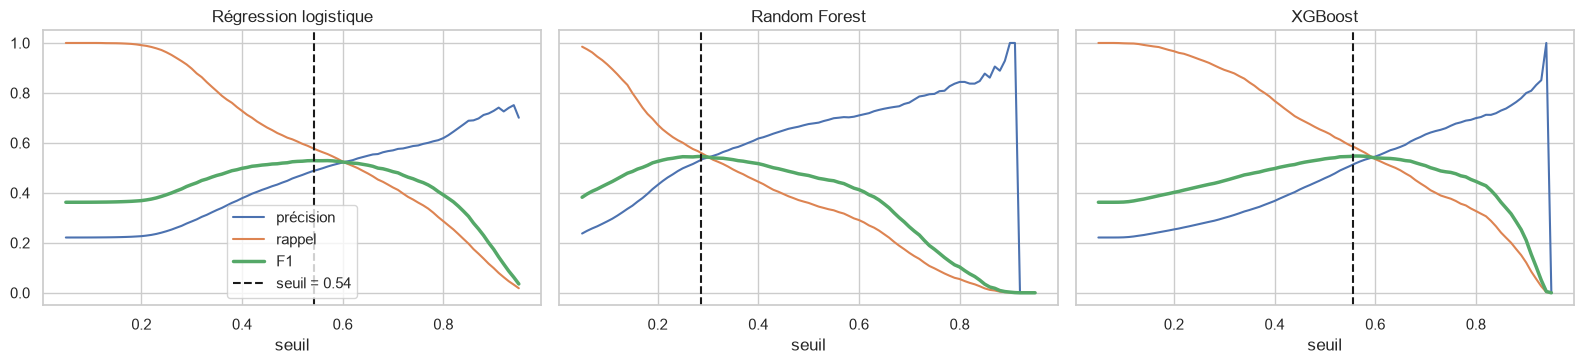

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
grid_thr = np.linspace(0.05, 0.95, 91)
for ax, name in zip(axes, searches):
    p, r, f = [], [], []
    for t in grid_thr:
        pred = oof[name] >= t
        p.append(precision_score(y_train, pred, zero_division=0))
        r.append(recall_score(y_train, pred))
        f.append(f1_score(y_train, pred))
    ax.plot(grid_thr, p, label="précision")
    ax.plot(grid_thr, r, label="rappel")
    ax.plot(grid_thr, f, label="F1", lw=2.5)
    ax.axvline(thresholds[name], color="k", ls="--", label=f"seuil = {thresholds[name]:.2f}")
    ax.set_title(name)
    ax.set_xlabel("seuil")
axes[0].legend()
plt.tight_layout()
show("06_thresholds")

Compromis classique : **baisser le seuil augmente le rappel** (on détecte plus de défauts) **au prix de la précision** (on signale à tort plus de bons clients). Le seuil « F1 optimal » est un point de départ neutre ; en production, il se règle selon le coût relatif d'un défaut non détecté (perte en capital) et d'un bon client refusé (manque à gagner). Voir la section 11.

## 9. Évaluation finale sur le jeu de test

Les trois modèles (hyperparamètres et seuil fixés sur le train) sont évalués **une seule fois** sur le jeu de test. Métriques :

- **ROC-AUC** et **Gini** (= 2 x AUC - 1, la métrique standard du scoring bancaire) ;
- **KS** (écart maximal entre les distributions de score des défauts et des non-défauts) ;
- **PR-AUC** (*average precision*), plus informative que le ROC-AUC en cas de déséquilibre ;
- **Brier** (qualité de la probabilité, plus bas = mieux) ;
- précision, rappel, F1 de la classe « défaut » et accuracy au seuil choisi.

In [28]:
test_proba = {n: s.best_estimator_.predict_proba(X_test)[:, 1] for n, s in searches.items()}


def ks_stat(y_true, proba):
    fpr, tpr, _ = roc_curve(y_true, proba)
    return float(np.max(tpr - fpr))


rows = []
for name, p in test_proba.items():
    pred = p >= thresholds[name]
    auc = roc_auc_score(y_test, p)
    rows.append({
        "modèle": name,
        "ROC-AUC": auc, "Gini": 2 * auc - 1, "KS": ks_stat(y_test, p),
        "PR-AUC": average_precision_score(y_test, p), "Brier": brier_score_loss(y_test, p),
        "seuil": thresholds[name],
        "précision": precision_score(y_test, pred), "rappel": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred), "accuracy": accuracy_score(y_test, pred),
    })
results = pd.DataFrame(rows).set_index("modèle")
results.round(4)

,ROC-AUC,Gini,KS,PR-AUC,Brier,seuil,précision,rappel,F1,accuracy
modèle,,,,,,,,,,
Régression logistique,0.7760,0.5520,0.4439,0.4938,0.1904,0.5431,0.4949,0.5905,0.5385,0.7761
Random Forest,0.7967,0.5935,0.4509,0.5676,0.1311,0.2865,0.5309,0.5762,0.5526,0.7936
XGBoost,0.7988,0.5976,0.4547,0.5723,0.1779,0.5566,0.5209,0.6011,0.5581,0.7894


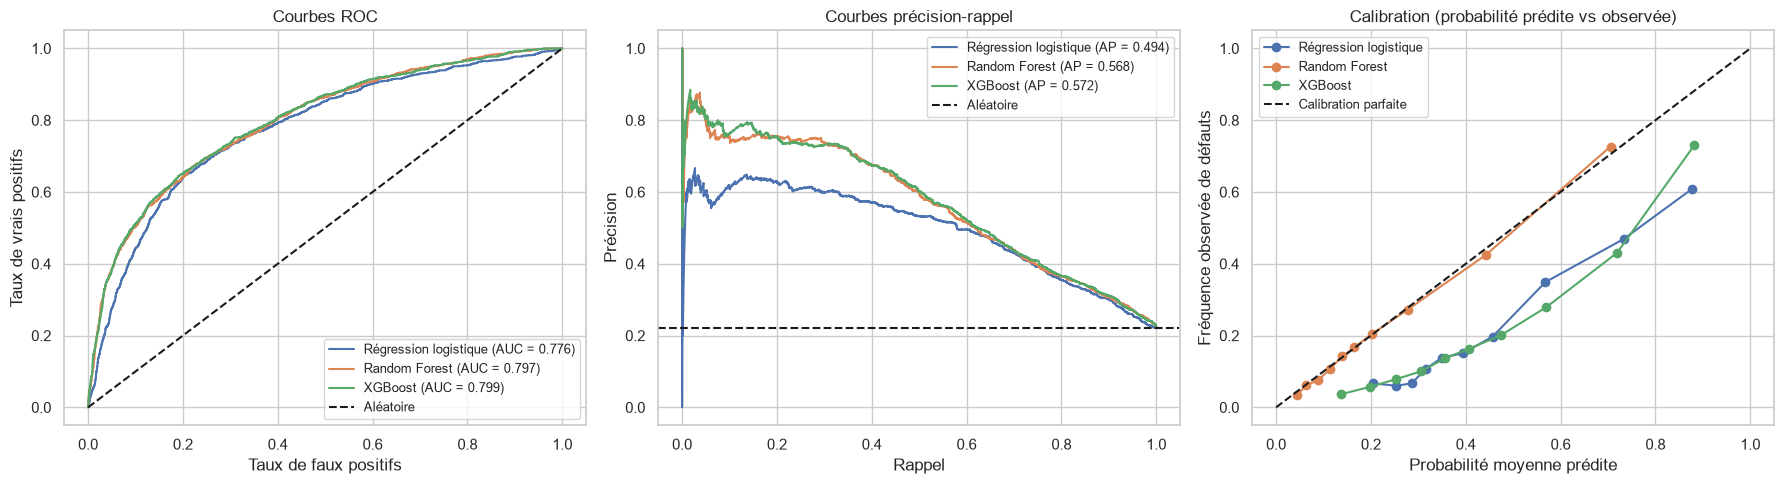

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = dict(zip(searches, sns.color_palette()[:3]))

for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=colors[name], label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, color=colors[name], label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    axes[2].plot(mean_pred, frac_pos, "o-", color=colors[name], label=name)

axes[0].plot([0, 1], [0, 1], "k--", label="Aléatoire")
axes[0].set(title="Courbes ROC", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs")
axes[1].axhline(y_test.mean(), color="k", ls="--", label="Aléatoire")
axes[1].set(title="Courbes précision-rappel", xlabel="Rappel", ylabel="Précision")
axes[2].plot([0, 1], [0, 1], "k--", label="Calibration parfaite")
axes[2].set(title="Calibration (probabilité prédite vs observée)", xlabel="Probabilité moyenne prédite", ylabel="Fréquence observée de défauts")
for ax in axes:
    ax.legend(loc="best", fontsize=9)
plt.tight_layout()
show("07_roc_pr_calibration")

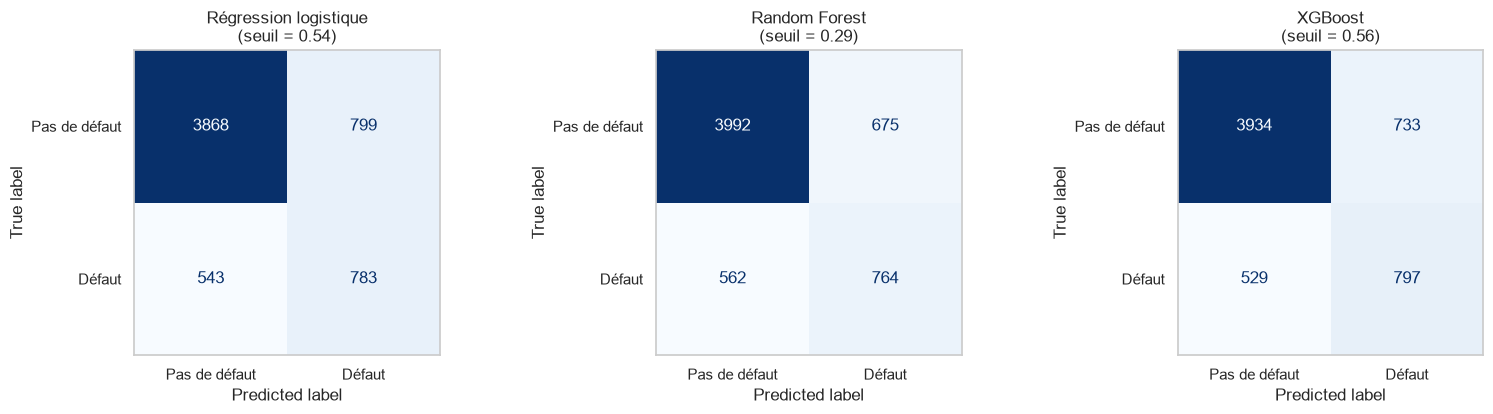

=== Régression logistique
               precision    recall  f1-score   support

Pas de défaut      0.877     0.829     0.852      4667
       Défaut      0.495     0.590     0.539      1326

     accuracy                          0.776      5993
    macro avg      0.686     0.710     0.695      5993
 weighted avg      0.792     0.776     0.783      5993

=== Random Forest
               precision    recall  f1-score   support

Pas de défaut      0.877     0.855     0.866      4667
       Défaut      0.531     0.576     0.553      1326

     accuracy                          0.794      5993
    macro avg      0.704     0.716     0.709      5993
 weighted avg      0.800     0.794     0.797      5993

=== XGBoost
               precision    recall  f1-score   support

Pas de défaut      0.881     0.843     0.862      4667
       Défaut      0.521     0.601     0.558      1326

     accuracy                          0.789      5993
    macro avg      0.701     0.722     0.710      5993
 

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, (name, p) in zip(axes, test_proba.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, p >= thresholds[name], display_labels=["Pas de défaut", "Défaut"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name}\n(seuil = {thresholds[name]:.2f})")
    ax.grid(False)
plt.tight_layout()
show("08_confusion")

for name, p in test_proba.items():
    print(f"=== {name}")
    print(classification_report(y_test, p >= thresholds[name], target_names=["Pas de défaut", "Défaut"], digits=3))

**Lecture.** Random Forest et XGBoost sont au coude à coude et nettement au-dessus de la régression logistique sur toutes les métriques de classement (ROC-AUC, Gini, KS, PR-AUC). Au seuil choisi, les trois modèles détectent 58 à 60 % des défauts, avec une précision de 50 à 53 % : le gain des modèles d'arbres se voit surtout dans la qualité du classement (et, pour le Random Forest, dans le **Brier**).

**Attention au Brier de la régression logistique et de XGBoost** : la première a été retenue avec `class_weight="balanced"`, le second avec `scale_pos_weight` ≈ 3,5 (rapport entre non-défauts et défauts), ce qui gonfle volontairement les probabilités de défaut. Leurs probabilités sont donc surestimées (voir la courbe de calibration, sous la diagonale) et leur Brier n'est pas comparable à celui du Random Forest, qui n'est pas pondéré (0,131 contre 0,178 pour XGBoost). Cela n'affecte pas leur classement (ROC-AUC) ; une recalibration (Platt / isotonique) serait nécessaire pour les utiliser comme probabilités de défaut.

### 9.1 Les écarts entre modèles sont-ils significatifs ?

Avec ~6 000 clients de test (~1 330 défauts), le ROC-AUC d'un modèle a une marge d'incertitude de l'ordre de ±0,015 (IC à 95 %, voir ci-dessous). On l'estime par **bootstrap** (800 rééchantillonnages du test, les trois modèles sont évalués sur les mêmes échantillons, ce qui permet des comparaisons appariées).

In [31]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
n = len(y_arr)
B = 800
boot = {name: np.full(B, np.nan) for name in test_proba}
for b in range(B):
    idx = rng.integers(0, n, n)
    if y_arr[idx].min() == y_arr[idx].max():
        continue
    for name, p in test_proba.items():
        boot[name][b] = roc_auc_score(y_arr[idx], p[idx])

ci = pd.DataFrame({
    n_: {"ROC-AUC": roc_auc_score(y_test, test_proba[n_]),
         "IC 95 % bas": np.nanpercentile(b_, 2.5), "IC 95 % haut": np.nanpercentile(b_, 97.5)}
    for n_, b_ in boot.items()
}).T
display(ci.round(4))

names = list(boot)
print("\nDifférences appariées de ROC-AUC (bootstrap) :")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        d = boot[names[i]] - boot[names[j]]
        lo, hi = np.nanpercentile(d, [2.5, 97.5])
        verdict = "significatif" if (lo > 0 or hi < 0) else "non significatif"
        print(f"  {names[i]:22s} - {names[j]:22s} : {np.nanmean(d):+.4f}  IC95 % [{lo:+.4f}, {hi:+.4f}]  -> {verdict}")

,ROC-AUC,IC 95 % bas,IC 95 % haut
Régression logistique,0.7760,0.7603,0.7900
Random Forest,0.7967,0.7821,0.8101
XGBoost,0.7988,0.7844,0.8124



Différences appariées de ROC-AUC (bootstrap) :
  Régression logistique  - Random Forest          : -0.0210  IC95 % [-0.0282, -0.0141]  -> significatif
  Régression logistique  - XGBoost                : -0.0230  IC95 % [-0.0294, -0.0164]  -> significatif
  Random Forest          - XGBoost                : -0.0020  IC95 % [-0.0046, +0.0007]  -> non significatif


## 10. Interprétation des modèles

### 10.1 Régression logistique : odds ratios

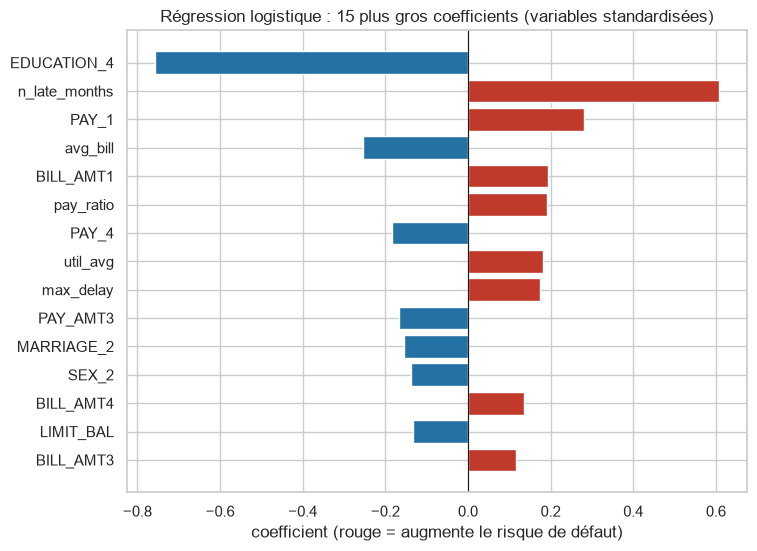

,coefficient,odds ratio (+1 écart-type)
EDUCATION_4,-0.757,0.469
n_late_months,0.607,1.835
PAY_1,0.280,1.324
avg_bill,-0.253,0.776
BILL_AMT1,0.193,1.213
pay_ratio,0.192,1.212
PAY_4,-0.183,0.833
util_avg,0.182,1.200
max_delay,0.175,1.191
PAY_AMT3,-0.166,0.847


In [32]:
lr_best = searches["Régression logistique"].best_estimator_
feat_names = lr_best.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_best.named_steps["clf"].coef_[0], index=feat_names)
odds = pd.DataFrame({"coefficient": coefs, "odds ratio (+1 écart-type)": np.exp(coefs)})
odds = odds.reindex(coefs.abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(8, 6))
top = odds.head(15).iloc[::-1]
ax.barh(top.index, top["coefficient"], color=["#c0392b" if c > 0 else "#2471a3" for c in top["coefficient"]])
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Régression logistique : 15 plus gros coefficients (variables standardisées)")
ax.set_xlabel("coefficient (rouge = augmente le risque de défaut)")
show("09_lr_coefficients")
odds.head(12).round(3)

Pour les variables numériques (standardisées), l'odds ratio se lit « effet d'une hausse d'un écart-type sur la cote (odds) de défaut, toutes choses égales par ailleurs » : par exemple `n_late_months` ≈ 1,8. Pour les variables *one-hot* (`EDUCATION_4`, `MARRIAGE_2`...), l'odds ratio compare la modalité à la modalité de référence (`SEX` = homme, `EDUCATION` = études supérieures, `MARRIAGE` = marié(e)) ; `EDUCATION_4` (« autres », ~470 clients) ressort en tête surtout parce que c'est un petit groupe peu risqué, pas parce que c'est le facteur le plus important. Parmi les variables continues, ce sont les indicateurs de retard (`n_late_months`, puis `PAY_1`) qui dominent. Les coefficients des factures (`BILL_AMT`, `avg_bill`) sont à manier avec prudence : à cause de la multicolinéarité, leurs signes ne sont pas interprétables isolément.

### 10.2 Importance par permutation (sur le jeu de test)

L'importance par permutation mesure la **baisse de ROC-AUC** quand on mélange aléatoirement les valeurs d'une variable. Elle s'applique de la même façon aux trois modèles, donc comparables, et elle est calculée sur les variables d'origine avant pré-traitement (une variable catégorielle = une seule barre).

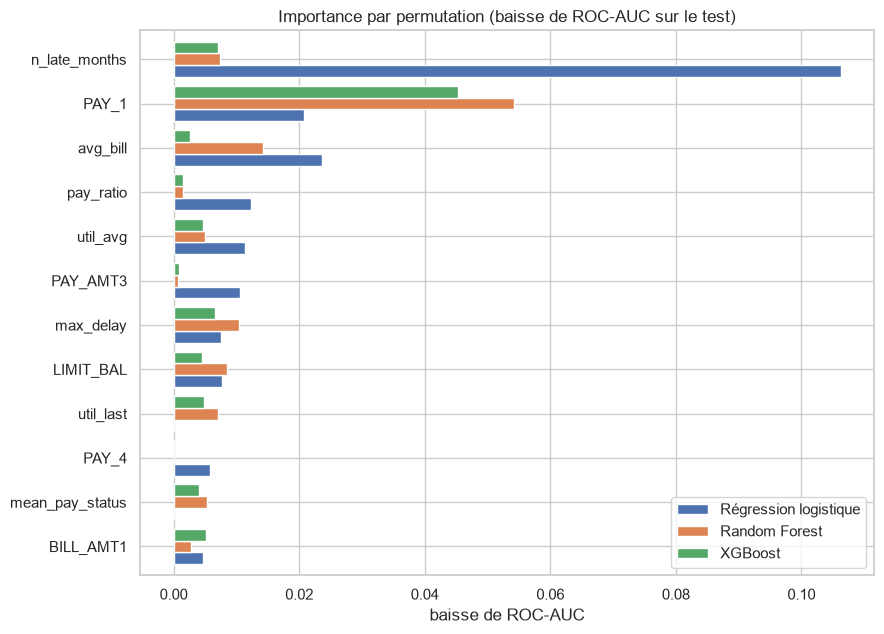

,Régression logistique,Random Forest,XGBoost
n_late_months,0.1062,0.0074,0.0071
PAY_1,0.0207,0.0542,0.0453
avg_bill,0.0237,0.0143,0.0025
pay_ratio,0.0123,0.0014,0.0015
util_avg,0.0114,0.0050,0.0047
PAY_AMT3,0.0106,0.0007,0.0009
max_delay,0.0076,0.0103,0.0066
LIMIT_BAL,0.0077,0.0086,0.0044
util_last,0.0000,0.0071,0.0049
PAY_4,0.0057,0.0000,0.0001


Variables socio-démographiques et plafond :


,Régression logistique,Random Forest,XGBoost
SEX,0.0006,0.0001,0.0006
EDUCATION,0.0026,0.0001,0.0013
MARRIAGE,0.0022,0.0005,0.0013
AGE,0.0006,0.0006,0.0002
LIMIT_BAL,0.0077,0.0086,0.0044


In [33]:
perm = {}
for name, s in searches.items():
    r = permutation_importance(s.best_estimator_, X_test, y_test, scoring="roc_auc",
                               n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
    perm[name] = pd.Series(r.importances_mean, index=X_test.columns)

perm_df = pd.DataFrame(perm)
top_feats = perm_df.max(axis=1).sort_values(ascending=False).head(12).index
plot_df = perm_df.loc[top_feats].iloc[::-1]

ax = plot_df.plot.barh(figsize=(9, 6.5), width=0.8)
ax.set_title("Importance par permutation (baisse de ROC-AUC sur le test)")
ax.set_xlabel("baisse de ROC-AUC")
plt.tight_layout()
show("10_permutation_importance")
display(perm_df.loc[top_feats].round(4))
print("Variables socio-démographiques et plafond :")
perm_df.loc[["SEX", "EDUCATION", "MARRIAGE", "AGE", "LIMIT_BAL"]].round(4)

Pour **Random Forest et XGBoost**, `PAY_1` (statut de remboursement du dernier mois) est de loin la variable la plus importante (en mélanger les valeurs fait perdre 0,045 à 0,054 de ROC-AUC) ; les suivantes (`avg_bill`, `max_delay`, `LIMIT_BAL`, `n_late_months`, `util_last`, `BILL_AMT1`, selon le modèle) pèsent beaucoup moins (0,004 à 0,014). La **régression logistique** s'appuie différemment sur l'information : elle s'en remet surtout à `n_late_months`, l'agrégat qu'on lui a fourni (elle ne peut pas fabriquer elle-même cette combinaison non linéaire des `PAY_x`). Les variables socio-démographiques (`SEX`, `EDUCATION`, `MARRIAGE`, `AGE`) pèsent très peu dans les trois modèles (voir le tableau ci-dessus). Remarque : l'importance par permutation d'une variable corrélée à d'autres (factures, retards) est « diluée » entre elles ; les valeurs sont à lire comme des ordres de grandeur.

## 11. Choix du modèle final

Le choix repose sur trois critères, dans cet ordre :

1. **Performance de généralisation** : ROC-AUC en validation croisée (train) puis confirmation sur le test ;
2. **Stabilité et sur-apprentissage** : écart train / CV, intervalle de confiance bootstrap ;
3. **Interprétabilité, calibration et coût de mise en production** : critères qui départagent les modèles quand les performances sont statistiquement proches.

Le jeu de test sert à **confirmer** le choix, pas à le faire : le classement est d'abord établi sur la validation croisée.

In [34]:
synthese = pd.DataFrame({
    "ROC-AUC CV (train)": cv_summary["ROC-AUC CV"],
    "écart train - CV": cv_summary["écart train - CV"],
    "ROC-AUC test": results["ROC-AUC"],
    "Gini test": results["Gini"],
    "KS test": results["KS"],
    "PR-AUC test": results["PR-AUC"],
    "Brier test": results["Brier"],
    "rappel test": results["rappel"],
    "F1 test": results["F1"],
})
synthese["rang CV"] = synthese["ROC-AUC CV (train)"].rank(ascending=False).astype(int)
synthese["rang test"] = synthese["ROC-AUC test"].rank(ascending=False).astype(int)
display(synthese.round(4))

FINAL_NAME = synthese["ROC-AUC CV (train)"].idxmax()
print(f"\nModèle retenu (meilleur ROC-AUC en validation croisée) : {FINAL_NAME}")

,ROC-AUC CV (train),écart train - CV,ROC-AUC test,Gini test,KS test,PR-AUC test,Brier test,rappel test,F1 test,rang CV,rang test
modèle,,,,,,,,,,,
Régression logistique,0.7648,0.0027,0.7760,0.5520,0.4439,0.4938,0.1904,0.5905,0.5385,3,3
Random Forest,0.7838,0.0464,0.7967,0.5935,0.4509,0.5676,0.1311,0.5762,0.5526,2,2
XGBoost,0.7856,0.0195,0.7988,0.5976,0.4547,0.5723,0.1779,0.6011,0.5581,1,1



Modèle retenu (meilleur ROC-AUC en validation croisée) : XGBoost


Modèle sauvegardé : models/xgboost_model.ubj + models/preprocessing.joblib (XGBoost, seuil = 0.557)


,clients,défauts,taux_défaut,proba_moyenne,lift,part_défauts_capturés_cumulée
décile,,,,,,
1,600,438,0.730,0.882,3.299,0.330
2,599,258,0.431,0.719,1.947,0.525
3,599,167,0.279,0.570,1.260,0.651
4,599,120,0.200,0.473,0.905,0.741
5,600,99,0.165,0.408,0.746,0.816
6,599,81,0.135,0.356,0.611,0.877
7,599,60,0.100,0.305,0.453,0.922
8,599,47,0.078,0.253,0.355,0.958
9,599,34,0.057,0.197,0.257,0.983


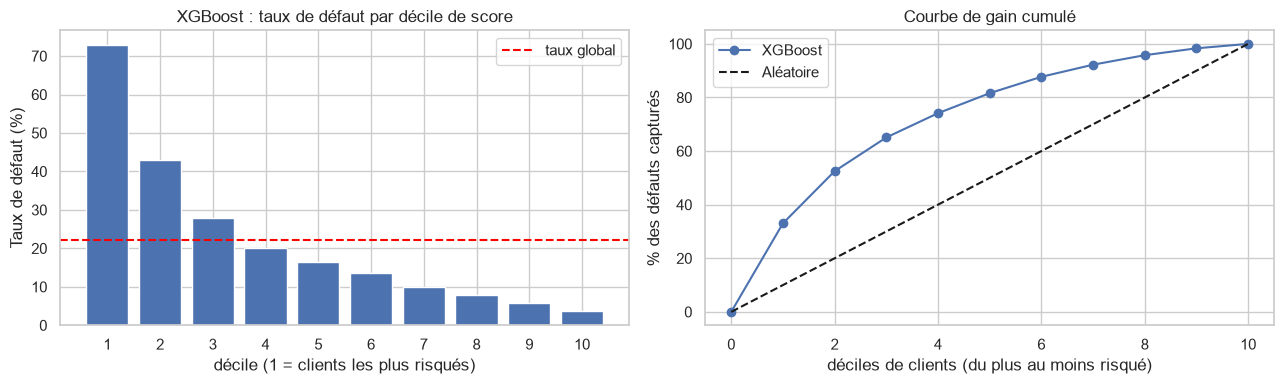

In [35]:
final_model = searches[FINAL_NAME].best_estimator_
final_proba = test_proba[FINAL_NAME]
final_thr = thresholds[FINAL_NAME]

import joblib

# Export portable : sérialiser le pipeline entier avec joblib embarque aussi la configuration interne de XGBoost
# (dont l'état de son générateur aléatoire, écrit dans le format texte de l'OS) : un modèle sauvegardé sous Linux
# ne se recharge pas sous Windows (« XGBoostError: input stream corrupted »). On enregistre donc le modèle XGBoost
# au format UBJSON (lisible partout) et, à part, le pré-traitement, le seuil et la liste des variables.
clf_final = final_model.named_steps["clf"]
if isinstance(clf_final, XGBClassifier):
    clf_final.save_model("models/xgboost_model.ubj")
    joblib.dump({"preprocessor": final_model.named_steps["prep"], "threshold": final_thr, "features": ALL_FEATS, "name": FINAL_NAME},
                "models/preprocessing.joblib")
    print(f"Modèle sauvegardé : models/xgboost_model.ubj + models/preprocessing.joblib ({FINAL_NAME}, seuil = {final_thr:.3f})")
else:  # modèles scikit-learn : le pipeline complet se sérialise sans difficulté
    joblib.dump({"model": final_model, "threshold": final_thr, "features": ALL_FEATS, "name": FINAL_NAME}, "models/final_model.joblib")
    print(f"Modèle sauvegardé : models/final_model.joblib ({FINAL_NAME}, seuil = {final_thr:.3f})")

# Table des déciles de risque : les clients sont classés par score décroissant puis découpés en 10 groupes
scored = pd.DataFrame({"proba": final_proba, "default": y_test.to_numpy()})
scored["décile"] = pd.qcut(scored["proba"].rank(method="first", ascending=False), 10, labels=range(1, 11))
dec = scored.groupby("décile", observed=True).agg(clients=("default", "size"), défauts=("default", "sum"),
                                                  taux_défaut=("default", "mean"), proba_moyenne=("proba", "mean"))
dec["lift"] = dec["taux_défaut"] / scored["default"].mean()
dec["part_défauts_capturés_cumulée"] = dec["défauts"].cumsum() / dec["défauts"].sum()
display(dec.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(dec.index.astype(str), dec["taux_défaut"] * 100, color=sns.color_palette()[0])
axes[0].axhline(scored["default"].mean() * 100, color="red", ls="--", label="taux global")
axes[0].set(title=f"{FINAL_NAME} : taux de défaut par décile de score", xlabel="décile (1 = clients les plus risqués)", ylabel="Taux de défaut (%)")
axes[0].legend()
axes[1].plot([0] + list(range(1, 11)), [0] + list(dec["part_défauts_capturés_cumulée"] * 100), "o-", label=FINAL_NAME)
axes[1].plot([0, 10], [0, 100], "k--", label="Aléatoire")
axes[1].set(title="Courbe de gain cumulé", xlabel="déciles de clients (du plus au moins risqué)", ylabel="% des défauts capturés")
axes[1].legend()
plt.tight_layout()
show("11_deciles_gain")

In [36]:
# Sensibilité au coût : si rater un défaut coûte `c` fois plus cher que refuser à tort un bon client,
# quel seuil minimise le coût total, et que devient le rappel ? (illustration, le ratio réel dépend de la banque)
oof_final = oof[FINAL_NAME]
rows = []
for c in [1, 2, 3, 5, 8]:
    ts = np.linspace(0.05, 0.9, 171)
    costs = [c * ((oof_final < t) & (y_train == 1)).sum() + ((oof_final >= t) & (y_train == 0)).sum() for t in ts]
    t_opt = ts[int(np.argmin(costs))]
    pred = final_proba >= t_opt
    rows.append({"coût d'un défaut raté / coût d'un refus à tort": c, "seuil optimal (train, OOF)": round(t_opt, 3),
                 "rappel test": recall_score(y_test, pred), "précision test": precision_score(y_test, pred),
                 "% de clients signalés": pred.mean()})
pd.DataFrame(rows).round(3)

,coût d'un défaut raté / coût d'un refus à tort,"seuil optimal (train, OOF)",rappel test,précision test,% de clients signalés
0,1,0.760,0.394,0.680,0.128
1,2,0.630,0.530,0.569,0.206
2,3,0.555,0.603,0.519,0.257
3,5,0.390,0.801,0.365,0.485
4,8,0.315,0.895,0.314,0.631


## 12. Conclusions

> Les chiffres ci-dessous proviennent de l'exécution sur le **fichier UCI complet** (30 000 clients, 29 965 après suppression de 35 doublons ; source indiquée en section 2.1).

**Résultats principaux**

- **Le statut de remboursement récent est le signal dominant.** Le taux de défaut passe de ~13-17 % pour un client à jour à ~34 % pour un mois de retard et ~70 % dès deux mois (`PAY_1`). Les variables socio-démographiques (sexe, éducation, situation maritale, âge) ont un pouvoir prédictif très faible.
- **Random Forest et XGBoost battent la régression logistique** : ROC-AUC test de 0,797 et 0,799 contre 0,776 (Gini 0,59 et 0,60 contre 0,55). L'écart de ~0,02 est statistiquement significatif (IC 95 % bootstrap de la différence : [0,014 ; 0,028] pour le Random Forest, [0,016 ; 0,029] pour XGBoost). Entre Random Forest et XGBoost, en revanche, **aucune différence significative** (-0,002, IC 95 % [-0,005 ; +0,001]).
- **Le feature engineering aide surtout le modèle linéaire** (+0,016 de ROC-AUC en validation croisée) et très peu les arbres (+0,002 et +0,003).
- **La régularisation fait la différence** : le Random Forest gagne ~0,02 de ROC-AUC en contraignant profondeur et taille des feuilles ; XGBoost est retenu avec des arbres peu profonds (profondeur 4), un faible taux d'apprentissage (0,02), de la régularisation (`min_child_weight`, `reg_lambda`, `gamma`) et une pondération des défauts (`scale_pos_weight` ≈ 3,5).

**Choix du modèle final : XGBoost**

- Meilleur ROC-AUC en validation croisée (0,786 ± 0,007), confirmé sur le test (0,799) ;
- sur-apprentissage bien plus faible que le Random Forest (écart train - CV de 0,020 contre 0,046) ;
- meilleur rappel et meilleur F1 au seuil choisi (0,60 et 0,558), modèle léger (< 1 Mo) et scoring rapide ;
- **mais** son avantage sur le Random Forest n'est pas significatif (0,002 de ROC-AUC en validation croisée, pour un écart-type de 0,007), et **ses probabilités sont mal calibrées** : la pondération des défauts les surestime (Brier 0,178 contre 0,131 pour le Random Forest, courbe de calibration sous la diagonale). Pour lire le score comme une probabilité de défaut, il faut le recalibrer (Platt / isotonique) ; si l'on veut des probabilités directement exploitables, le Random Forest est un choix tout aussi défendable. La régression logistique, moins performante, reste utile comme modèle de référence et pour l'explicabilité (odds ratios), très demandée en crédit réglementé ; ses probabilités doivent aussi être recalibrées (`class_weight="balanced"`).

**Lecture métier du score (jeu de test)**

- Au seuil de 0,557 (F1 optimal), le modèle détecte ~60 % des défauts avec une précision de ~52 % : 1 client signalé sur 2 fera effectivement défaut, contre 1 sur 4,5 en population générale.
- Le 1er décile de risque affiche un taux de défaut de ~73 % (lift ≈ 3,3) ; les 2 premiers déciles regroupent ~52 % des défauts, les 3 premiers ~65 %. Le dernier décile ne compte que ~3,7 % de défauts.
- Le seuil est un levier de **politique de risque**, pas une constante : si un défaut raté coûte 5 fois plus qu'un refus à tort, le seuil descend à ~0,39, le rappel monte à ~80 % et ~49 % des clients sont signalés (précision ~37 %).

**Limites et pistes d'amélioration**

- **Le plafond de performance est modeste** (ROC-AUC ≈ 0,80 pour les modèles d'arbres) : le dataset ne contient que six mois d'historique de remboursement et peu d'informations sur le client (pas de revenu, pas d'ancienneté, pas de données externes). Un modèle plus complexe n'ira probablement pas beaucoup plus loin sans nouvelles variables.
- Données de **Taïwan en 2005** (crise des cartes de crédit) : la transposition à un autre contexte ou à une autre période n'est pas garantie ; un suivi de dérive (PSI) serait nécessaire en production.
- **Les modalités `PAY_x` = -2 et 0 ne sont pas documentées** : l'interprétation retenue (pas de consommation / paiement minimum) est plausible mais non confirmée.
- **Le choix de `scale_pos_weight` dépend de la recherche aléatoire** : sur une copie à 24 000 clients, elle avait retenu `scale_pos_weight` = 1 et XGBoost avait des probabilités bien calibrées. Les écarts de l'ordre de 0,01 entre réglages ou entre modèles d'arbres sont dans la marge d'incertitude du test (IC à 95 % d'environ ± 0,015).
- Un seul découpage train / test a été utilisé : une validation croisée imbriquée donnerait une estimation plus robuste de l'erreur de généralisation.
- Pistes : recalibration des probabilités (Platt / isotonique), optimisation bayésienne (Optuna), interprétation locale par SHAP, analyse d'équité par sous-groupes (sexe, âge), seuil fondé sur les coûts réels de la banque, essai de LightGBM / CatBoost.
